In [215]:
import pandas as pd

In [216]:
import numpy as np

In [217]:
import matplotlib.pyplot as plt

In [218]:
import seaborn as sns

**DATA IMPORT AND SETUP**

In [219]:
df=pd.read_csv("social_media_engagement_5000.csv")

In [220]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [221]:
df.shape

(5000, 19)

In [222]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [223]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [224]:
df["posted_at"]=pd.to_datetime(df["posted_at"])

C:\Users\hp\AppData\Local\Temp\ipykernel_11924\1507373682.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"]=pd.to_datetime(df["posted_at"])


In [225]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [226]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,NaN,230927.884535,5.318029


**Data Cleaning**

In [227]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [228]:
df["age"]=df["age"].fillna(df["age"].mean())

In [229]:
df["gender"]=df["gender"].fillna(df["gender"].mode()[0])

In [230]:
df["likes"]=df["likes"].fillna(df["likes"].mean())

In [231]:
df["comments"]=df["comments"].fillna(df["comments"].mean())

In [232]:
df["shares"]=df["shares"].fillna(df["shares"].mean())

In [233]:
df["sentiment"]=df["sentiment"].fillna(df["sentiment"].mode()[0])

In [234]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [235]:
df.duplicated().sum()

np.int64(0)

In [236]:
df[["age","likes","shares","comments"]]=df[["age","likes","shares","comments"]].astype(int)

In [237]:
df.dtypes

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [238]:
col=["post_type","post_category","device_type","sentiment"]
for i in col:
    df[i]=df[i].str.title()

In [239]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,Text,Travel,13487,1502,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518


In [240]:
df["hashtags"].value_counts()

hashtags
#tech                          201
#love                          176
#fitness                       174
#music                         165
#fun                           163
                              ... 
#love #foodie #fashion           1
#fashion #music #tech            1
#music #lifestyle #travel        1
#lifestyle #reels #tech          1
#foodie #lifestyle #fashion      1
Name: count, Length: 761, dtype: int64

In [241]:
df["sentiment"].value_counts()

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64

**Data Exploration using Pandas**

In [242]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372


In [243]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,Text,Travel,13487,1502,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527


In [244]:
df.shape

(5000, 19)

In [245]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [246]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [247]:
df.dtypes

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [248]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.042400,1502.189800,1002.610600,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.000000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10107.000000,1502.000000,1002.000000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293011,856.392854,570.852972,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [249]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,Text,Travel,13487,1502,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518


In [250]:
df[["gender","country","post_type","post_category","device_type","sentiment","hashtags"]].nunique()

gender             3
country           10
post_type          4
post_category      8
device_type        3
sentiment          3
hashtags         761
dtype: int64

In [251]:
df["post_type"].unique()

<ArrowStringArray>
['Image', 'Reel', 'Text', 'Video']
Length: 4, dtype: str

In [252]:
df["post_category"].unique()

<ArrowStringArray>
[  'Fitness',      'Food',      'Tech',    'Travel',   'Fashion', 'Lifestyle',
 'Education',     'Music']
Length: 8, dtype: str

In [253]:
df["device_type"].unique()

<ArrowStringArray>
['Mobile', 'Tablet', 'Desktop']
Length: 3, dtype: str

In [254]:
df["post_type"].value_counts()

post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64

In [255]:
df["post_category"].value_counts()

post_category
Fitness      675
Tech         665
Music        635
Education    631
Lifestyle    607
Travel       600
Fashion      594
Food         593
Name: count, dtype: int64

In [256]:
df["device_type"].value_counts()

device_type
Mobile     1684
Tablet     1658
Desktop    1658
Name: count, dtype: int64

In [257]:
df["gender"].value_counts()

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

In [258]:
df["country"].value_counts()

country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

In [259]:
correlation=df[["age","likes","comments","shares","watch_time_sec","impression_count","follower_count","engagement_rate"]].corr()

In [260]:
correlation

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
age,1.000000,-0.036322,-0.007284,0.013864,0.005542,0.013322,-0.024894,0.008039
likes,-0.036322,1.000000,-0.018424,0.004648,0.008711,0.007953,-0.022981,0.093520
comments,-0.007284,-0.018424,1.000000,0.006130,-0.016347,-0.009392,-0.011742,0.000046
shares,0.013864,0.004648,0.006130,1.000000,0.014672,-0.005086,-0.010738,0.021729
watch_time_sec,0.005542,0.008711,-0.016347,0.014672,1.000000,-0.004335,0.002761,-0.001148
impression_count,0.013322,0.007953,-0.009392,-0.005086,-0.004335,1.000000,-0.015513,-0.232226
follower_count,-0.024894,-0.022981,-0.011742,-0.010738,0.002761,-0.015513,1.000000,0.002292
engagement_rate,0.008039,0.093520,0.000046,0.021729,-0.001148,-0.232226,0.002292,1.000000


In [261]:
df.groupby("post_type")["likes"].mean().sort_values(ascending=False)

post_type
Video    10188.641633
Image    10104.903769
Text     10100.195181
Reel     10037.855027
Name: likes, dtype: float64

In [262]:
df.groupby("post_type")["impression_count"].mean().sort_values(ascending=False)

post_type
Reel     50462.598597
Text     49987.218474
Video    49862.014694
Image    49727.421812
Name: impression_count, dtype: float64

In [263]:
df.groupby("post_type")["engagement_rate"].median().sort_values(ascending=False)

post_type
Image    0.264375
Text     0.254932
Reel     0.247557
Video    0.247042
Name: engagement_rate, dtype: float64

In [264]:
# Post type image has higher engagement rate.
# Post type reel has higher impression count.

In [265]:
df.groupby("post_category")["engagement_rate"].median().sort_values(ascending=False)

post_category
Education    0.278319
Fashion      0.258818
Music        0.256149
Food         0.253283
Travel       0.250857
Tech         0.250818
Lifestyle    0.249015
Fitness      0.248481
Name: engagement_rate, dtype: float64

In [313]:
df.groupby("post_category")["impression_count"].median().sort_values(ascending=False)

post_category
Tech         52682.0
Food         51030.0
Music        50171.0
Fitness      49839.0
Travel       49602.0
Fashion      48855.5
Lifestyle    48460.0
Education    48322.0
Name: impression_count, dtype: float64

In [266]:
# The post category 'education' has max engagement rate.
# the post category tec has higher impression count.

In [267]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [268]:
df.groupby("country")["post_category"].get_group("Brazil").value_counts()

post_category
Lifestyle    70
Food         66
Fitness      65
Travel       64
Fashion      63
Tech         63
Education    58
Music        55
Name: count, dtype: int64

In [269]:
# Brazil has highest average engagement rate with lifestyle as most frequent post category

In [270]:
df.groupby("country")["impression_count"].mean().sort_values(ascending=False)

country
India        52462.386916
France       51727.673387
USA          51263.872255
UK           51119.393509
Japan        49616.135593
Brazil       49193.174603
UAE          48928.413519
Canada       48703.150097
Germany      48605.406122
Australia    48346.383367
Name: impression_count, dtype: float64

In [271]:
df.groupby("country")["post_category"].get_group("India").value_counts()

post_category
Tech         81
Education    72
Lifestyle    70
Music        65
Food         64
Fashion      64
Fitness      60
Travel       59
Name: count, dtype: int64

In [272]:
# India has highest impression count with tech as the post category with highest frequency.

In [273]:
df.groupby("gender")["engagement_rate"].median().sort_values(ascending=False)

gender
Male      0.265486
Female    0.254395
Other     0.246352
Name: engagement_rate, dtype: float64

In [274]:
df.groupby("post_category")["gender"].value_counts()

post_category  gender
Education      Male      226
               Other     205
               Female    200
Fashion        Male      227
               Female    186
               Other     181
Fitness        Male      263
               Other     224
               Female    188
Food           Male      226
               Other     189
               Female    178
Lifestyle      Male      225
               Female    198
               Other     184
Music          Male      222
               Other     213
               Female    200
Tech           Male      251
               Female    212
               Other     202
Travel         Male      209
               Female    208
               Other     183
Name: count, dtype: int64

In [275]:
df.groupby("is_verified")["engagement_rate"].median().sort_values(ascending=False)

is_verified
False    0.256149
True     0.236700
Name: engagement_rate, dtype: float64

In [276]:
df.groupby("is_verified")["impression_count"].mean().sort_values(ascending=False)

is_verified
True     50747.343685
False    49935.288244
Name: impression_count, dtype: float64

In [ ]:
#Engagement rate higher for non verified id but imprssion count for verified.

In [279]:
df.groupby("device_type")["impression_count"].mean()

device_type
Desktop    50934.068758
Mobile     49516.948931
Tablet     49597.971049
Name: impression_count, dtype: float64

In [ ]:
# Desktop users have more impression count

In [280]:
df.groupby("sentiment")["impression_count"].mean().sort_values(ascending=False)

sentiment
Positive    50248.107441
Negative    50191.960417
Neutral     49515.971185
Name: impression_count, dtype: float64

In [281]:
df.groupby("sentiment")["engagement_rate"].median().sort_values(ascending=False)

sentiment
Negative    0.255769
Positive    0.254328
Neutral     0.251941
Name: engagement_rate, dtype: float64

In [ ]:
#Engagement rate almost same for all sentiment.

In [283]:
df["engagement_score"]=df["likes"]+df["comments"]+df["shares"]

In [284]:
df["hashtag_count"]=df["hashtags"].str.count("#")

In [285]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_score,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,...,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,8522,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,...,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,16163,1
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,...,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,6161,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,7482,3
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,...,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,16717,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,...,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761,20060,2
4996,22100,38,Other,UAE,677076,Reel,Education,16924,2734,1583,...,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155,21241,2
4997,67021,63,Female,USA,273595,Text,Travel,13487,1502,167,...,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688,15156,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,...,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518,19896,3


**Data Visualisation**

<function matplotlib.pyplot.show(close=None, block=None)>

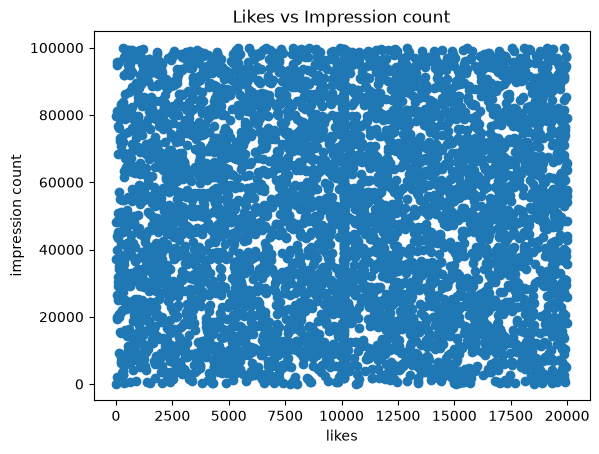

In [286]:
plt.scatter(x=df["likes"],y=df["impression_count"])
plt.title("Likes vs Impression count")
plt.xlabel("likes")
plt.ylabel("impression count")
plt.show
           
          

<function matplotlib.pyplot.show(close=None, block=None)>

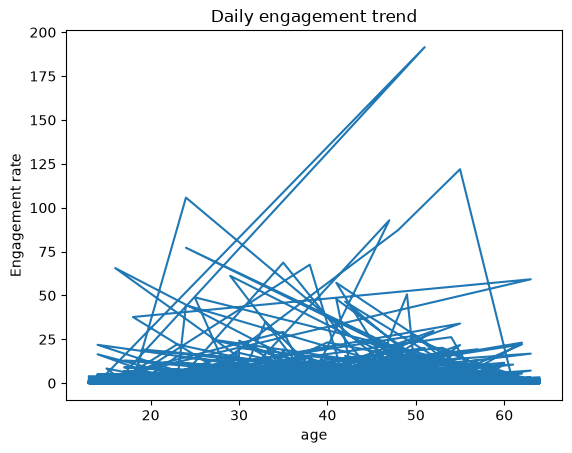

In [288]:
plt.plot("age","engagement_rate",data=df)
plt.title("Daily engagement trend")
plt.xlabel("age")
plt.ylabel("Engagement rate")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

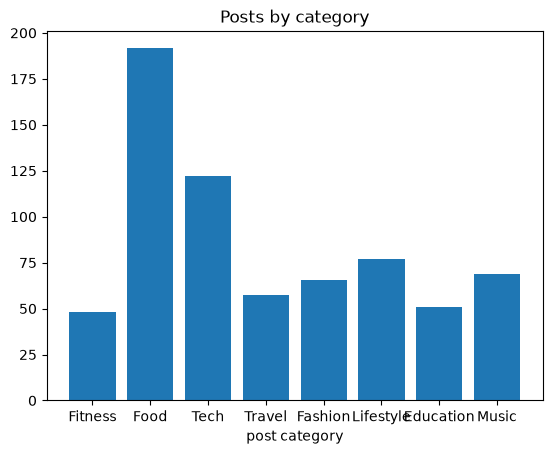

In [302]:
plt.bar("post_category","engagement_rate",data=df)
plt.title("Posts by category")
plt.xlabel("post category")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

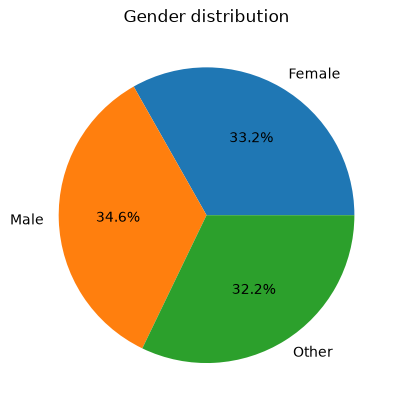

In [303]:
plt.pie(df.groupby("gender")["engagement_rate"].median(),labels=df["gender"].unique(),autopct="%.1f%%")
plt.title("Gender distribution")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

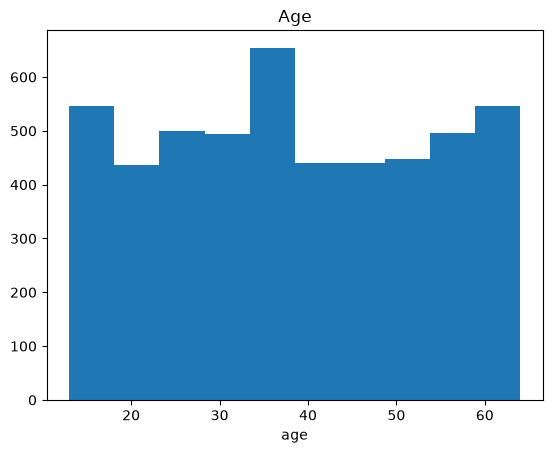

In [304]:
plt.hist(df["age"],bins=10)
plt.title("Age")
plt.xlabel("age")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

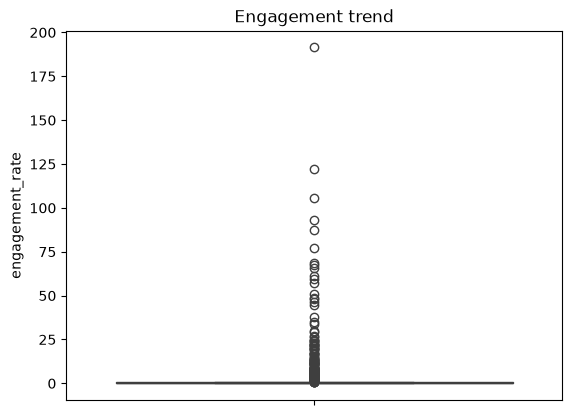

In [305]:
sns.boxplot(df["engagement_rate"],patch_artist=True)
plt.title("Engagement trend")
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

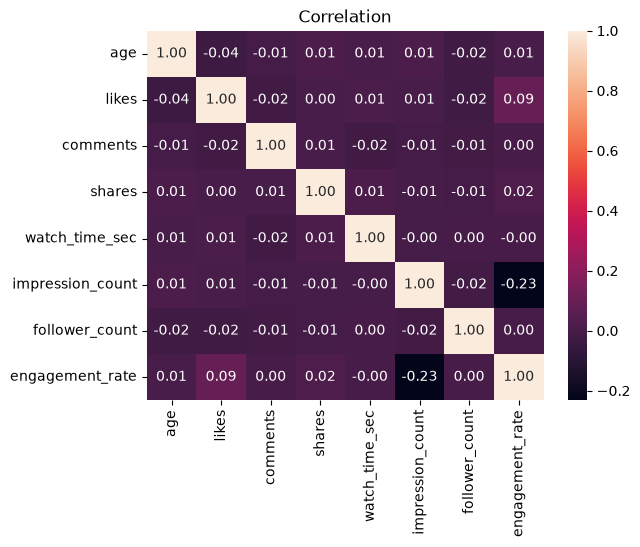

In [293]:
sns.heatmap(correlation,annot=True,fmt=".2f")
plt.title("Correlation")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

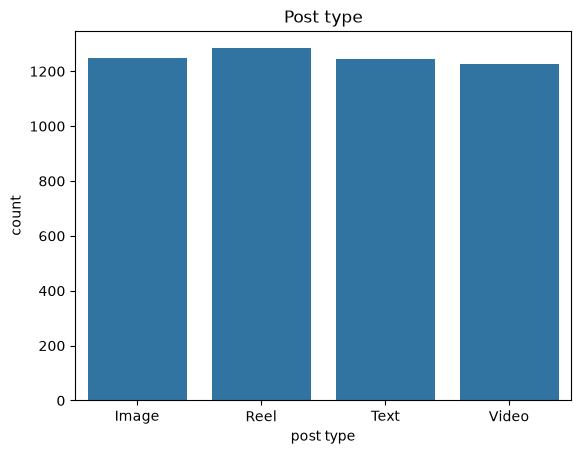

In [306]:
sns.countplot(x="post_type",data=df)
plt.title("Post type")
plt.xlabel("post type")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

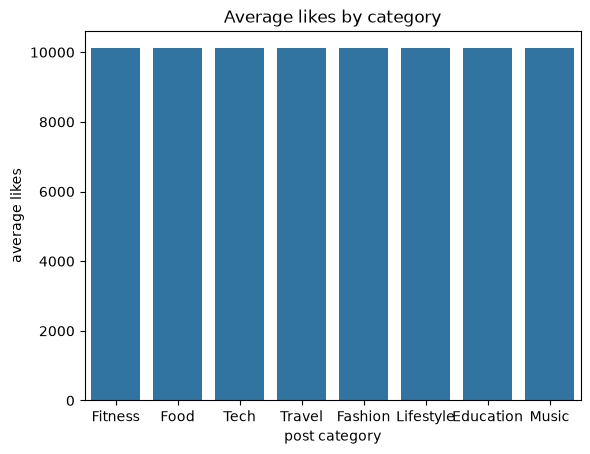

In [315]:
sns.barplot(x=df["post_category"],y=df["likes"].mean())
plt.title("Average likes by category")
plt.xlabel("post category")
plt.ylabel("average likes")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

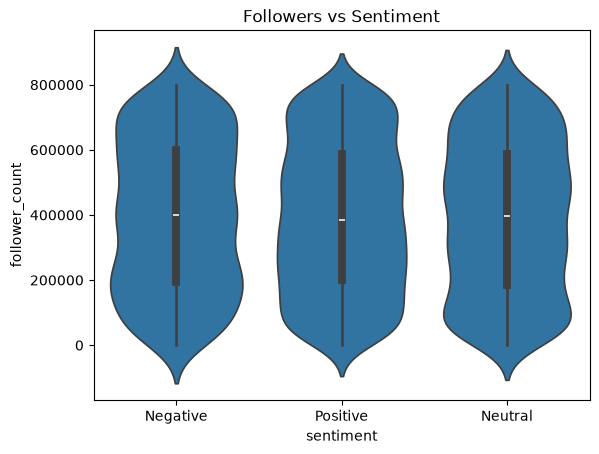

In [314]:
sns.violinplot(data=df,x="sentiment",y="follower_count")
plt.title("Followers vs Sentiment")
plt.show

**Statistical Analysis**

In [297]:
df[["age","likes","comments","shares","impression_count","follower_count","engagement_rate"]].describe()

,age,likes,comments,shares,impression_count,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,38.440400,10107.042400,1502.189800,1002.610600,50013.732800,393698.224800,0.964356
std,14.687151,5702.293011,856.392854,570.852972,28844.939104,230927.884535,5.318029
min,13.000000,10.000000,0.000000,0.000000,105.000000,87.000000,0.006363
25%,26.000000,5235.000000,792.000000,511.000000,24988.250000,194480.000000,0.145781
50%,38.000000,10107.000000,1502.000000,1002.000000,49934.500000,388982.000000,0.253896
75%,51.000000,14959.000000,2235.250000,1483.000000,74662.250000,589744.250000,0.504794
max,64.000000,19998.000000,2999.000000,1999.000000,99995.000000,799533.000000,191.504348


In [298]:
##The mean age of the users is 38.
## Engagement rate has outliers.

In [299]:
correlation

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
age,1.000000,-0.036322,-0.007284,0.013864,0.005542,0.013322,-0.024894,0.008039
likes,-0.036322,1.000000,-0.018424,0.004648,0.008711,0.007953,-0.022981,0.093520
comments,-0.007284,-0.018424,1.000000,0.006130,-0.016347,-0.009392,-0.011742,0.000046
shares,0.013864,0.004648,0.006130,1.000000,0.014672,-0.005086,-0.010738,0.021729
watch_time_sec,0.005542,0.008711,-0.016347,0.014672,1.000000,-0.004335,0.002761,-0.001148
impression_count,0.013322,0.007953,-0.009392,-0.005086,-0.004335,1.000000,-0.015513,-0.232226
follower_count,-0.024894,-0.022981,-0.011742,-0.010738,0.002761,-0.015513,1.000000,0.002292
engagement_rate,0.008039,0.093520,0.000046,0.021729,-0.001148,-0.232226,0.002292,1.000000


In [300]:
## Age is negatively correlated with likes,comments and follower count.
## More likes,shares and comments does not ensure follower count.
## Engagement rate and impression count follows negative correlation.

**FINAL INSIGHTS**

In [301]:
# The post type "image" has got the highest engagement rate.
# The post type "reel" has got higher impression_count.
# Education is the best performing post category .
# Brazil has highest average engagement rate with lifestyle as most frequent post category.
# India has highest impression count with tech as the post category with highest frequency.
# Likes , cooments and follower count decreases with increase in age . Also very less positive correlation with engagement rate.
# Engagement rate is higher for non verified id but impression count are higher for users with verified id.
# Desktop shows higher impression count.
# Postive sentiment has got higher impression count. But engagement rate is almost equal for positive,negative and neutral.

